# Maximum de vraisemblance et comparaison avec la loi log-normale

La régression sur le log-rang a des défauts (voir `regressions.ipynb`). L'alternative standard est le **maximum de vraisemblance** : on suppose que les tailles au-dessus d'un seuil $x_{min}$ suivent une loi de Pareto, $P(X > x) = (x_{min}/x)^{\zeta}$, et on estime ζ par
$$\hat\zeta = \frac{n}{\sum_i \ln (x_i / x_{min})} ,$$
avec pour écart-type $\hat\zeta/\sqrt{n}$. Reste à choisir le seuil : on prend celui qui rend la loi de Pareto ajustée la plus proche des données au sens de la distance de Kolmogorov-Smirnov (Clauset, Shalizi et Newman, 2009).

**Zipf contre log-normale.** La loi log-normale décrit souvent aussi bien, voire mieux, l'ensemble de la distribution des tailles de villes (Eeckhout, 2004), et sur la queue une log-normale très étalée imite une loi de puissance. On compare les deux lois, toutes deux tronquées en $x_{min}$, par le test du rapport de vraisemblance de Vuong :

- le rapport est positif si la loi de Pareto s'ajuste mieux, négatif si c'est la log-normale ;
- la *p-value* dit si cette différence est significative : une p-value élevée signifie que les données ne permettent pas de trancher.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from zipf_villes import ajuste_pareto, charge_populations, compare_lognormale

DATA = Path("../data")
IMAGES = Path("../images")
com_pop, aav, msa = charge_populations(str(DATA))

jeux = {
    "communes": com_pop["PTOT"].to_numpy(),
    "aires d'attraction": aav["PTOT"].to_numpy(),
    "MSA": msa["pop"].to_numpy(),
}

## Exposant et seuil

Pour chaque jeu, on cherche le seuil par Kolmogorov-Smirnov (en gardant au moins 30 villes au-dessus) puis on estime l'exposant.

In [2]:
ajustements = {nom: ajuste_pareto(tailles) for nom, tailles in jeux.items()}
pd.DataFrame(
    {
        nom: {
            "exposant": a.exposant,
            "écart-type": a.erreur,
            "seuil x_min": a.xmin,
            "villes au-dessus du seuil": a.n,
            "distance KS": a.ks,
        }
        for nom, a in ajustements.items()
    }
).T.round(3)

,exposant,écart-type,seuil x_min,villes au-dessus du seuil,distance KS
communes,1.187,0.026,5494.0,2044.0,0.024
aires d'attraction,1.406,0.207,261457.0,46.0,0.065
MSA,0.801,0.043,111871.0,350.0,0.054


## Zipf ou log-normale ?

In [3]:
comparaisons = {
    nom: compare_lognormale(tailles, ajustements[nom].xmin)
    for nom, tailles in jeux.items()
}
pd.DataFrame(
    {
        nom: {
            "rapport de vraisemblance": c.rapport,
            "statistique de Vuong": c.statistique,
            "p-value": c.p_value,
            "AIC(Pareto) − AIC(log-normale)": c.delta_aic,
            "mu (log-normale)": c.mu,
            "sigma (log-normale)": c.sigma,
        }
        for nom, c in comparaisons.items()
    }
).T.round(4)

,rapport de vraisemblance,statistique de Vuong,p-value,AIC(Pareto) − AIC(log-normale),mu (log-normale),sigma (log-normale)
communes,-9.1680,-2.3574,0.0184,16.3361,3.3438,2.3964
aires d'attraction,0.0025,0.1679,0.8666,-2.0049,-303.1886,15.0203
MSA,-5.8411,-2.2206,0.0264,9.6821,9.4783,2.3124


Lecture : un rapport positif avec une p-value faible donne l'avantage à la loi de Pareto, un rapport négatif avec une p-value faible à la log-normale ; avec une p-value élevée (disons supérieure à 0,05), les données ne permettent pas de les départager.

## Fonction de survie empirique et ajustements

On trace $P(X > x)$ en échelle log-log : une loi de Pareto est une droite de pente −ζ. En pointillés, la droite ajustée au-dessus du seuil.

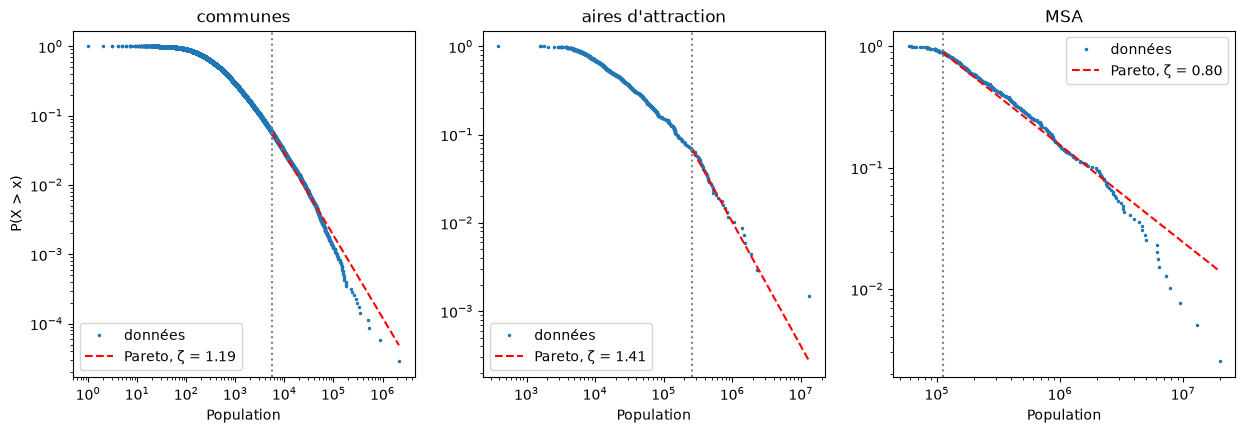

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (nom, tailles) in zip(axes, jeux.items(), strict=True):
    x = np.sort(tailles)[::-1]
    survie = np.arange(1, len(x) + 1) / len(x)
    a = ajustements[nom]
    ax.loglog(x, survie, ".", markersize=3, label="données")
    xs = np.array([a.xmin, x[0]])
    proportion = a.n / len(x)
    ax.loglog(
        xs,
        proportion * (a.xmin / xs) ** a.exposant,
        "r--",
        label=f"Pareto, ζ = {a.exposant:.2f}",
    )
    ax.axvline(a.xmin, color="gray", linestyle=":")
    ax.set_title(nom)
    ax.set_xlabel("Population")
    ax.legend()
axes[0].set_ylabel("P(X > x)")
fig.savefig(IMAGES / "survie.png", dpi=120, bbox_inches="tight")
plt.show()

## Références

- Clauset, Shalizi et Newman (2009), *Power-law distributions in empirical data*, SIAM Review.
- Eeckhout (2004), *Gibrat's law for (all) cities*, American Economic Review.
- Gabaix (1999), *Zipf's law for cities: an explanation*, Quarterly Journal of Economics.
- Le package [powerlaw](https://github.com/jeffalstott/powerlaw) fournit une implémentation de référence de ces méthodes : les fonctions de `zipf_villes` donnent les mêmes valeurs (voir `tests/test_estimation.py`).